# Week 1 — Run it, then discover a real truth yourself

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Louai-Mohamed/flyrank-ml-internship/blob/main/notebooks/01_first_look_and_discovery.ipynb?flush_cache=true)

By the end of this notebook you will have:
1. **Run a real ML pipeline** on real (anonymized) search data and watched a learned model beat a hand-written rule.
2. **Rediscovered a real finding yourself** in ~10 lines of pandas.

No prior ML needed. Everything runs on the small anonymized dataset that ships with this repo — no credentials, no private data.

## 0. Setup (Colab or local)
On Colab this clones the repo and installs requirements. Locally it just moves to the repo root.

In [1]:
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Louai-Mohamed/flyrank-ml-internship"
REPO_DIR = "flyrank-ml-internship"

if IN_COLAB:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    # find the repo root from wherever this kernel started
    while not os.path.isdir("data/raw") and os.getcwd() != "/":
        os.chdir("..")

print("Working dir:", os.getcwd())
assert os.path.exists("data/raw/content_refresh_anonymized.csv"), "starter CSV not found — are you at the repo root?"
print("Starter data found. You're ready.")

Working dir: .
Starter data found. You're ready.


## 1. Run the whole pipeline

This runs `scripts/run_all.py`: prepare features → baseline rule → train 3 models → evaluate → PDF.
It takes ~1 minute on the 30,000-row sample.

In [2]:
# Watch it work — each of the 5 steps prints live as it runs (~1 minute total).
!{sys.executable} scripts/run_all.py



▶ Step 1/5 — Prepare features — clean the data, build the feature vector, define the label
Prepared 30,000 rows from 30,000 raw rows
Wrote data\processed\refresh_feature_vector.csv

▶ Step 2/5 — Baseline — a transparent hand-written rule to beat
Wrote baseline queue: data\processed\baseline_refresh_queue.csv
Top-50 declining rate (full data, not the evaluated holdout Precision@50): 0.340

▶ Step 3/5 — Train — logistic regression, decision tree, random forest (client-holdout split)
Trained 3 models on 30,000 rows
Split strategy: client_holdout
Best model: random_forest
Wrote predictions: data\processed\model_predictions.csv
Wrote model results: outputs\model_results.json

▶ Step 4/5 — Evaluate — ranked refresh queue, charts, and the Markdown report
Wrote final refresh queue: outputs\refresh_queue.csv
Wrote model report: outputs\model_report.md
Wrote charts in: outputs\charts

▶ Step 5/5 — Report — a shareable PDF summary
Wrote PDF report: outputs\flyrank_refresh_model_results.pdf

Pipe

### What just happened?
The pipeline ranked every page for "refresh review" two ways: a **hand-written rule baseline** and a **learned model**. Let's compare them on **Precision@50** — of the top 50 pages each says to fix first, how many are actually declining?

In [3]:
import json
res = json.load(open("outputs/model_results.json"))

base = res["baseline"]["baseline_precision_at_50"]
rf   = res["models"]["random_forest"]["precision_at_50"]

print(f"Hand-written rule  Precision@50: {base:.3f}   (~{round(base*50)} of the top 50 right)")
print(f"Random forest      Precision@50: {rf:.3f}   (~{round(rf*50)} of the top 50 right)")
print(f"\nThe learned model roughly {rf/base:.1f}x the rule on this metric.")
print("Validation split used:", res["split_strategy"], "(pages from a client are never in both train and test)")

Hand-written rule  Precision@50: 0.240   (~12 of the top 50 right)
Random forest      Precision@50: 0.680   (~34 of the top 50 right)

The learned model roughly 2.8x the rule on this metric.
Validation split used: client_holdout (pages from a client are never in both train and test)


You just ran a real ML system on real search data and saw a learned ranking beat a fixed rule. Now open `outputs/model_report.md` and skim it — that Markdown report is the *shape* of what your own capstone should produce.

## 2. Discover a real truth yourself

The safest, most satisfying early wins are **things you find in the data** — un-leakable, and they *are* the core lesson. Run the three cells below. Each is ~10 lines of pandas and each overturns a common SEO belief.

Every number is **computed live from the shipped CSV** — nothing is hardcoded.

In [4]:
import pandas as pd, numpy as np
df = pd.read_csv("data/raw/content_refresh_anonymized.csv")
print(df.shape[0], "rows,", df.shape[1], "columns")
df.head(3)

30000 rows, 44 columns


,content_id,client_id,search_volume,competition,competition_level,cpc,content_type,main_intent,word_count,char_count,...,char_count_tier,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,impression_tier,position_tier,trend_direction,trend_pct
0,content_304f48230142,client_f369cb89fc,10.0,0.67,HIGH,2.05,keyword article,transactional,3221.0,20457.0,...,15000-25000,0.76,10.6,5.88,4.55,0.0,good,striking,down,-41.4
1,content_a1fb4e703a9e,client_4e07408562,90.0,0.01,LOW,0.05,keyword article,informational,2481.0,15562.0,...,15000-25000,0.05,20.3,0.00,10.00,0.0,good,page_3_5,down,-57.7
2,content_9aa793d4d895,client_7f2253d7e2,0.0,0.00,LOW,0.00,keyword article,informational,3515.0,23643.0,...,15000-25000,0.09,36.5,0.00,28.57,0.0,good,page_3_5,down,-60.9


### Discovery A — "High search volume means more traffic." Does it?

In [5]:
corr = df["search_volume"].corr(df["impressions_90d"])
print(f"Correlation between search_volume and impressions_90d: {corr:.3f}")
print("Near zero -> keyword search volume barely predicts the traffic a page actually gets.")

Correlation between search_volume and impressions_90d: 0.001
Near zero -> keyword search volume barely predicts the traffic a page actually gets.


### Discovery B — the CTR cliff by position
Click-through rate is not flat: it collapses as you move down the results.

position_tier
page_1      0.3548
top_3       0.3341
striking    0.2558
page_3_5    0.1424
deep        0.0554


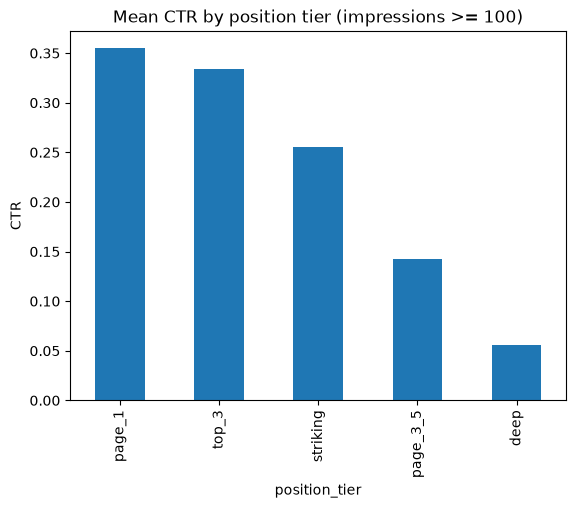

In [6]:
visible = df[df["impressions_90d"] >= 100]
ctr_by_pos = visible.groupby("position_tier")["ctr"].mean().sort_values(ascending=False)
print(ctr_by_pos.round(4).to_string())
ctr_by_pos.plot(kind="bar", title="Mean CTR by position tier (impressions >= 100)", ylabel="CTR");

### Discovery C — is longer content the lever?
Compare word count for **declining** vs **growing** pages.

In [7]:
wc = df.groupby("trend_direction")["word_count"].median()
print(wc.round(0).to_string())
print("\n'down' vs 'up' pages have almost the same median word count -> length is not the lever.")

trend_direction
down      2909.0
flat      2698.0
new       2239.0
stable    2912.0
up        2848.0

'down' vs 'up' pages have almost the same median word count -> length is not the lever.


## 3. 🔧 Your turn

Pick **one** of these and write a few lines below. This is your Week-1 discovery — you'll reference it in your Week-1 research-question write-up (on the InternHQ board).

- Redo Discovery A but only for pages with `impressions_90d > 0` — does the correlation change?
- In Discovery B, which `content_type` has the worst CTR *at the same position tier*?
- Find another belief to test: does `content_age_days` relate to `trend_direction`? Does `avg_position` relate to `ctr`?

**Rules:** describe what you observe as *observed / directional* — never "I proved Google's algorithm." Keep client data out of anything you publish.

### My Week-1 discovery — the same position tier does not mean the same click-through

Discovery B showed CTR collapsing as you move down the results. That is a **tier average**, and a tier
average hides the interesting part: at the *same* position tier, one content type gets a fraction of the
clicks another one gets.

**My question:** within the same `position_tier`, does `content_type` change the click-through rate?

**Why it matters:** if it does, "this page has low CTR, rewrite it" is the wrong first move for a whole
class of pages. A human reviewer would triage by page type instead of by tier alone. I also redo
Discovery A on pages that actually get traffic, and test `content_age_days` against `trend_direction` —
so the finding is checked against the two obvious explanations (keyword volume, and age).

In [8]:
# 🔧 Your turn — setup (everything below is computed live from the shipped CSV)
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv("data/raw/content_refresh_anonymized.csv")
df["is_declining"] = df["trend_direction"].str.lower().eq("down").astype(int)

print(f"{len(df):,} pages | {df['client_id'].nunique()} clients | "
      f"{df['is_declining'].mean():.1%} declining | content types: {', '.join(sorted(df['content_type'].unique()))}")

30,000 pages | 32 clients | 54.2% declining | content types: comparison article, feedly article, keyword article


#### Test 1 — redo Discovery A, but only where traffic was measurable

**Claim:** *high keyword search volume means more traffic.*

The first pass used every row. Two things could hide a real relationship: pages with almost no traffic
(where the outcome is noise) and the heavy tail (a few giant pages drag a Pearson correlation). So I
re-run it on progressively more visible slices and add a rank (Spearman) correlation that is immune to
the tail; a `log1p` transform covers the third angle.

In [9]:
claim = "high keyword search volume means more traffic"
print(f"Claim under test: {claim}\n")
print(f"{'slice':<24}{'pages':>8}{'Pearson':>10}{'Spearman':>10}")
for label, floor in [("all rows", 0), (">= 100 impressions", 100),
                     (">= 500 impressions", 500), (">= 1,000 impressions", 1000)]:
    frame = df[df["impressions_90d"] >= floor]
    print(f"{label:<24}{len(frame):>8,}"
          f"{frame['search_volume'].corr(frame['impressions_90d']):>10.4f}"
          f"{frame['search_volume'].corr(frame['impressions_90d'], method='spearman'):>10.4f}")

visible = df[df["impressions_90d"] >= 500]
print(f"\nlog1p Pearson on the >=500 slice: "
      f"{np.log1p(visible['search_volume']).corr(np.log1p(visible['impressions_90d'])):.4f}")
print("Blank search_volume rows drop out of every correlation above:",
      f"{df['search_volume'].isna().sum():,} of {len(df):,} pages have no keyword data at all.")

Claim under test: high keyword search volume means more traffic



slice                      pages   Pearson  Spearman


all rows                  30,000    0.0012   -0.0291
>= 100 impressions        22,006   -0.0002   -0.0596
>= 500 impressions        16,726   -0.0009   -0.0756
>= 1,000 impressions      13,512   -0.0010   -0.0741

log1p Pearson on the >=500 slice: -0.0689
Blank search_volume rows drop out of every correlation above: 2,468 of 30,000 pages have no keyword data at all.


**Verdict — FALSE.** The correlation stays between −0.08 and 0.00 on every slice and every transform:
restricting to visible pages and switching to a rank correlation does not rescue it, it makes it slightly
*negative*. Keyword search volume is not a usable proxy for the traffic a page actually earns —
the two are near-independent in this slice. (Observed, on 30,000 anonymized pages.)

#### Test 2 — at the same position tier, which content type loses the clicks?

**Claim:** *two pages in the same position tier earn the same click-through, whatever their type.*

Rates need denominators, so I show the page count, the mean per-page CTR **and** the click-weighted CTR
(total clicks ÷ total impressions) — averaging per-page rates over-weights tiny pages. Any cell under
50 pages gets no verdict, that is noise wearing a costume.

In [10]:
visible = df[df["impressions_90d"] >= 100].copy()
visible["clicks_est"] = visible["impressions_90d"] * visible["ctr"] / 100  # clicks implied by the shipped rate

grouped = visible.groupby(["position_tier", "content_type"])
table = pd.DataFrame({
    "pages": grouped.size(),
    "mean_ctr_pct": grouped["ctr"].mean().round(3),
    "click_weighted_ctr_pct": (100 * grouped["clicks_est"].sum()
                               / grouped["impressions_90d"].sum()).round(3),
}).reset_index()
table["usable"] = np.where(table["pages"] >= 50, "yes", "n<50 — no verdict")
print(table.to_string(index=False))

tier_order = ["top_3", "page_1", "striking", "page_3_5", "deep"]
usable = table[table["pages"] >= 50]
contrast = (usable[usable["content_type"].isin(["comparison article", "keyword article"])]
            .pivot(index="position_tier", columns="content_type",
                   values="click_weighted_ctr_pct")
            .reindex([t for t in tier_order if t in set(usable["position_tier"])]))
contrast["keyword ÷ comparison"] = (contrast["keyword article"]
                                    / contrast["comparison article"]).round(2)
print("\nComparison vs keyword article in the same tier (click-weighted CTR %):")
print(contrast.round(3).to_string())

position_tier       content_type  pages  mean_ctr_pct  click_weighted_ctr_pct            usable
         deep     feedly article     10         0.044                   0.035 n<50 — no verdict
         deep    keyword article    869         0.056                   0.040               yes
       page_1 comparison article    226         0.141                   0.078               yes
       page_1     feedly article    221         0.905                   0.500               yes
       page_1    keyword article   8186         0.346                   0.350               yes
     page_3_5 comparison article     63         0.094                   0.095               yes
     page_3_5     feedly article     41         0.166                   0.239 n<50 — no verdict
     page_3_5    keyword article   5954         0.143                   0.155               yes
     striking comparison article     76         0.147                   0.159               yes
     striking     feedly article     75 

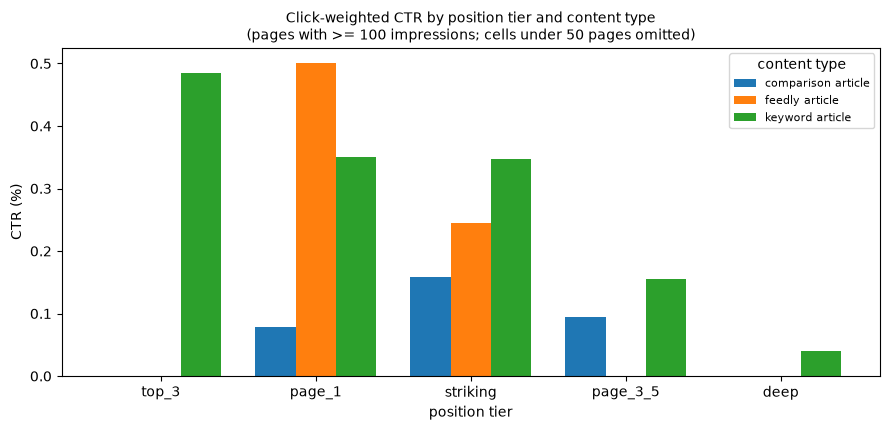

In [11]:
# The same numbers as a picture — saved into work/figures/ for the write-up
pivot = usable.pivot(index="position_tier", columns="content_type",
                     values="click_weighted_ctr_pct")
pivot = pivot.reindex([tier for tier in tier_order if tier in pivot.index])

ax = pivot.plot(kind="bar", figsize=(9, 4.4), width=0.78)
ax.set_title("Click-weighted CTR by position tier and content type\n"
             "(pages with >= 100 impressions; cells under 50 pages omitted)", fontsize=10)
ax.set_xlabel("position tier")
ax.set_ylabel("CTR (%)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title="content type", fontsize=8)
plt.tight_layout()
os.makedirs("work/figures", exist_ok=True)
plt.savefig("work/figures/w01_ctr_by_content_type_position.png", dpi=150, bbox_inches="tight")
plt.show()

**Verdict — CONFIRMED (directional), and it is not the tier talking.** At `page_1` — the tier where the
contrast is cleanest on sample size — a **comparison article** converts 0.08% of its impressions into
clicks against 0.35% for a **keyword article** (226 pages vs 8,186): a **4.5x** gap in the same tier, and
the ratio column shows the same direction at `striking` and `page_3_5`. `feedly article` pages look best on
CTR but are barely visible (median 4 impressions), so that estimate rests on a handful of big pages;
`top_3` cells are under the floor and get no verdict at all.

So: a page can sit on page one and still be the wrong page type for that spot. Decision-support, not proof
— the next test has to rule out age and size.

#### Test 3 — is it just age, or size? (confound check)

**Claim:** *the CTR gap is explained by the type being younger / shorter / less visible.*

If comparison articles are systematically younger and smaller, then "type" is a stand-in for "new page
still finding its audience" and the finding is worthless. Check the profile first, then hold age constant.
(Cells are a cross-cut here, so the sample-size floor is 30 pages, not 50.)

In [12]:
profile = df.groupby("content_type").agg(
    pages=("is_declining", "size"),
    median_age_days=("content_age_days", "median"),
    median_word_count=("word_count", "median"),
    median_impressions=("impressions_90d", "median"),
    declining_rate=("is_declining", "mean"),
).round(2)
print(profile.to_string())

page1 = visible[visible["position_tier"] == "page_1"].copy()
page1["age_band"] = pd.cut(page1["content_age_days"], bins=[89, 180, 365, 730, 10_000],
                           labels=["90-180", "181-365", "366-730", "731+"])

matched = page1.groupby(["age_band", "content_type"], observed=True).agg(
    pages=("clicks_est", "size"),
    clicks=("clicks_est", "sum"),
    impressions=("impressions_90d", "sum"),
)
matched["click_weighted_ctr_pct"] = (100 * matched["clicks"] / matched["impressions"]).round(3)
matched["usable"] = np.where(matched["pages"] >= 30, "yes", "n<30 — no verdict")
print("\nSame tier (page_1), same age band — does the gap survive?")
print(matched[["pages", "click_weighted_ctr_pct", "usable"]].to_string())

                    pages  median_age_days  median_word_count  median_impressions  declining_rate
content_type                                                                                     
comparison article    697            151.0             3155.0               107.0            0.57
feedly article       2096            291.0             1237.0                 4.0            0.29
keyword article     27207            236.0             2902.0               955.0            0.56

Same tier (page_1), same age band — does the gap survive?
                             pages  click_weighted_ctr_pct usable
age_band content_type                                            
90-180   comparison article    178                   0.056    yes
         feedly article         63                   0.507    yes
         keyword article      3780                   0.382    yes
181-365  comparison article     48                   0.277    yes
         feedly article        158                   0.

**Verdict — MIXED, and the mixed part is the finding.** Age and size do not explain it away: comparison
articles are *longer* (median 3,155 words), so "thin content" cannot be the story. But holding age constant
splits the result in two:

- **youngest band (90–180 days):** 0.06% vs 0.38% for keyword articles — the full gap survives, n=178 vs 3,780.
- **181–365 days:** 0.28% vs 0.36% — most of the gap is gone, n=48 vs 2,509. Above the cross-cut floor, so
  it is reportable, but it is a rough estimate.

So the honest reading is **not** "comparison articles always lose clicks". It is *new comparison articles
start with a click-through deficit that mostly closes within about six months*. That is a launch-window
pattern, which suggests `content_age_days` — not page type alone — is the thing to model.

#### What I take from this into the Week-1 write-up

1. **Search volume is not traffic.** Correlations stay within ±0.08 across every slice and transform, so
   keyword volume is not a candidate feature for prioritizing pages. *(FALSE)*
2. **Position tier is not a performance guarantee.** Inside `page_1`, a comparison article earns about a
   quarter of a keyword article's click-through — direction solid, magnitude approximate. *(CONFIRMED, directional)*
3. **The gap is age-shaped, not type-shaped.** It is largest for pages under ~180 days old and largely gone
   by a year, so `content_age_days` interacts with type and belongs in the model as an interaction, not as
   a verdict about a page type. *(MIXED)*

**Language check:** these are *observed* associations in an anonymized 30,000-page slice — no causal claim,
no claim about Google's algorithm, and no client-identifying detail anywhere above. The figure is saved at
`work/figures/w01_ctr_by_content_type_position.png`.

**Next test for Week 3:** hold age *and* word count constant, then see whether the type gap is still there —
and re-run the whole thing on the full warehouse release instead of the 30k starter slice.

### Save your work
**Colab:** *File → Save a copy in GitHub* (writes to your own repo — that's your submission) and *File → Save a copy in Drive* (so the session doesn't evaporate).

Next: `02_your_first_readable_model.ipynb` — where the model becomes a rule you can read.